In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve)

In [12]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/network_intrusion_20000.csv")

In [13]:
df.head()

,SourcePort,DestinationPort,Protocol,PacketSize,PacketCount,FlowDuration,BytesTransferred,ConnectionAttempts,FailedConnections,TrafficRate,SourceIPReputation,DestinationIPReputation,NetworkService,AttackType
0,33554,20,TCP,638,39,3.831,13763,1,1,3592.53,0.627,0.602,DNS,Normal
1,11392,143,ICMP,228,37,15.114,8340,2,1,551.81,0.834,0.743,SSH,Normal
2,56160,53,TCP,482,36,29.058,23863,2,0,821.22,0.877,0.501,HTTP,Attack
3,1044,80,TCP,750,39,6.609,21414,4,1,3240.13,0.936,0.827,DNS,Normal
4,15966,20,TCP,450,44,6.999,14685,1,0,2098.16,0.530,0.967,HTTPS,Normal


In [14]:
df.shape

(20000, 14)

In [15]:
df.columns

Index(['SourcePort', 'DestinationPort', 'Protocol', 'PacketSize',
       'PacketCount', 'FlowDuration', 'BytesTransferred', 'ConnectionAttempts',
       'FailedConnections', 'TrafficRate', 'SourceIPReputation',
       'DestinationIPReputation', 'NetworkService', 'AttackType'],
      dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   SourcePort               20000 non-null  int64  
 1   DestinationPort          20000 non-null  int64  
 2   Protocol                 20000 non-null  object 
 3   PacketSize               20000 non-null  int64  
 4   PacketCount              20000 non-null  int64  
 5   FlowDuration             20000 non-null  float64
 6   BytesTransferred         20000 non-null  int64  
 7   ConnectionAttempts       20000 non-null  int64  
 8   FailedConnections        20000 non-null  int64  
 9   TrafficRate              20000 non-null  float64
 10  SourceIPReputation       20000 non-null  float64
 11  DestinationIPReputation  20000 non-null  float64
 12  NetworkService           20000 non-null  object 
 13  AttackType               20000 non-null  object 
dtypes: float64(4), int64(7

In [17]:
df.describe()

,SourcePort,DestinationPort,PacketSize,PacketCount,FlowDuration,BytesTransferred,ConnectionAttempts,FailedConnections,TrafficRate,SourceIPReputation,DestinationIPReputation
count,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000
mean,33199.088900,1115.74220,753.224150,35.974200,8.014686,27084.30170,2.003200,0.399950,1.859018e+04,0.713071,0.748112
std,18656.859504,2388.13609,338.773659,5.904437,8.057291,15721.40464,1.408683,0.608365,6.546381e+04,0.159795,0.145357
min,1028.000000,20.00000,40.000000,16.000000,0.050000,551.00000,0.000000,0.000000,2.007000e+01,0.083000,0.133000
25%,17036.000000,22.00000,517.000000,32.000000,2.334000,15652.50000,1.000000,0.000000,1.861630e+03,0.609000,0.656000
50%,33309.000000,80.00000,755.000000,36.000000,5.506000,24721.50000,2.000000,0.000000,4.365920e+03,0.736000,0.770000
75%,49323.500000,443.00000,990.000000,40.000000,11.145000,36172.75000,3.000000,1.000000,1.116201e+04,0.837250,0.860000
max,65534.000000,8080.00000,1500.000000,60.000000,120.000000,116077.00000,9.000000,4.000000,1.465000e+06,0.997000,0.999000


In [18]:
df.isnull().sum()

SourcePort                 0
DestinationPort            0
Protocol                   0
PacketSize                 0
PacketCount                0
FlowDuration               0
BytesTransferred           0
ConnectionAttempts         0
FailedConnections          0
TrafficRate                0
SourceIPReputation         0
DestinationIPReputation    0
NetworkService             0
AttackType                 0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df["AttackType"].value_counts()

AttackType
Normal    14804
Attack     5196
Name: count, dtype: int64

In [31]:
X = df.drop("AttackType", axis=1)
y = df["AttackType"].map({
    "Normal": 0,
    "Attack": 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20000, 13)
Target Shape: (20000,)


In [32]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['SourcePort', 'DestinationPort', 'PacketSize', 'PacketCount', 'FlowDuration', 'BytesTransferred', 'ConnectionAttempts', 'FailedConnections', 'TrafficRate', 'SourceIPReputation', 'DestinationIPReputation']
Categorical Columns: ['Protocol', 'NetworkService']


In [33]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (16000, 13)
Testing Shape: (4000, 13)


In [34]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [35]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [36]:
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['SourcePort','DestinationPort','Protocol',...,'SourceIPReputation', 'DestinationIPReputation','NetworkService']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

In [37]:
y_pred = xgb_model.predict(X_test)
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred})

prediction_results.head(10)

,Actual,Predicted
0,1,0
1,1,0
2,0,0
3,0,0
4,0,0
5,1,0
6,1,1
7,1,0
8,0,0
9,0,0


In [38]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.75475
Precision: 0.5747422680412371
Recall   : 0.21462945139557266
F1 Score : 0.31254379817799577


In [39]:
print(classification_report(y_test,y_pred,target_names=["Normal", "Attack"]))

              precision    recall  f1-score   support

      Normal       0.77      0.94      0.85      2961
      Attack       0.57      0.21      0.31      1039

    accuracy                           0.75      4000
   macro avg       0.67      0.58      0.58      4000
weighted avg       0.72      0.75      0.71      4000



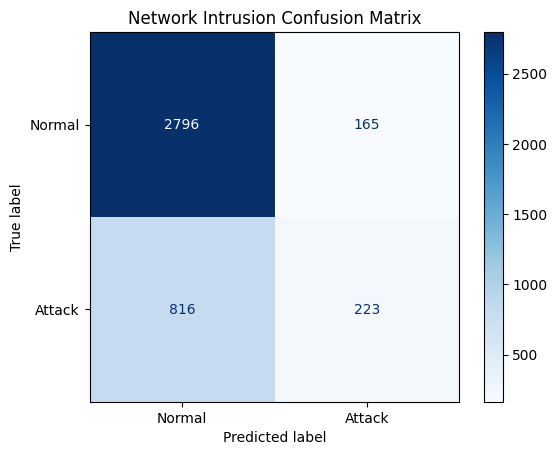

In [40]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"])
disp.plot(cmap="Blues")
plt.title("Network Intrusion Confusion Matrix")
plt.show()

In [41]:
y_prob = xgb_model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", round(auc, 4))

ROC-AUC Score: 0.6808


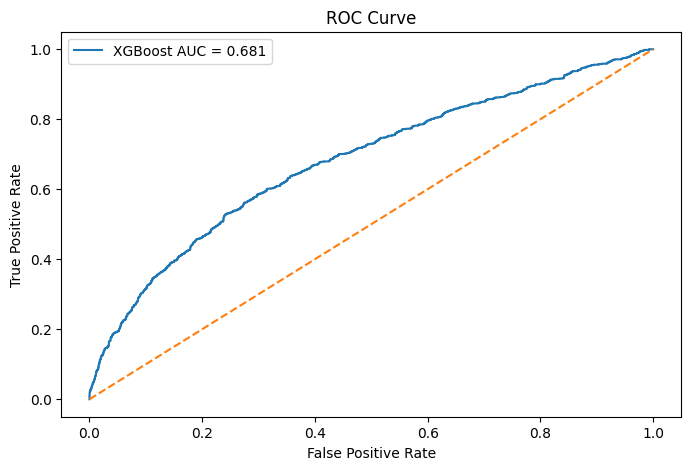

In [42]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"XGBoost AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [44]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0]}
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__learning_rate': [0.01, 0.03, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__min_child_weight': [1, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best est

In [45]:
print("Best Parameters:", random_search.best_params_)
print("Best CV F1 Score:", random_search.best_score_)

Best Parameters: {'classifier__subsample': 0.7, 'classifier__n_estimators': 400, 'classifier__min_child_weight': 5, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.7}
Best CV F1 Score: 0.30434148560444574


In [46]:
best_model = random_search.best_estimator_
tuned_pred = best_model.predict(X_test)
print("Tuned Model Classification Report:")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["Normal", "Attack"]))

Tuned Model Classification Report:
              precision    recall  f1-score   support

      Normal       0.78      0.93      0.85      2961
      Attack       0.54      0.24      0.33      1039

    accuracy                           0.75      4000
   macro avg       0.66      0.58      0.59      4000
weighted avg       0.71      0.75      0.71      4000



In [47]:
print("Tuned Accuracy:", accuracy_score(y_test, tuned_pred))
print("Tuned Precision:", precision_score(y_test, tuned_pred))
print("Tuned Recall:", recall_score(y_test, tuned_pred))
print("Tuned F1 Score:", f1_score(y_test, tuned_pred))

Tuned Accuracy: 0.74875
Tuned Precision: 0.5369565217391304
Tuned Recall: 0.2377285851780558
Tuned F1 Score: 0.3295530353569046


In [48]:
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = best_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
7,num__FailedConnections,0.187993
11,cat__Protocol_ICMP,0.063497
6,num__ConnectionAttempts,0.062953
8,num__TrafficRate,0.052170
1,num__DestinationPort,0.040446
15,cat__NetworkService_FTP,0.038982
12,cat__Protocol_TCP,0.038810
14,cat__NetworkService_DNS,0.038771
13,cat__Protocol_UDP,0.038535
9,num__SourceIPReputation,0.038359


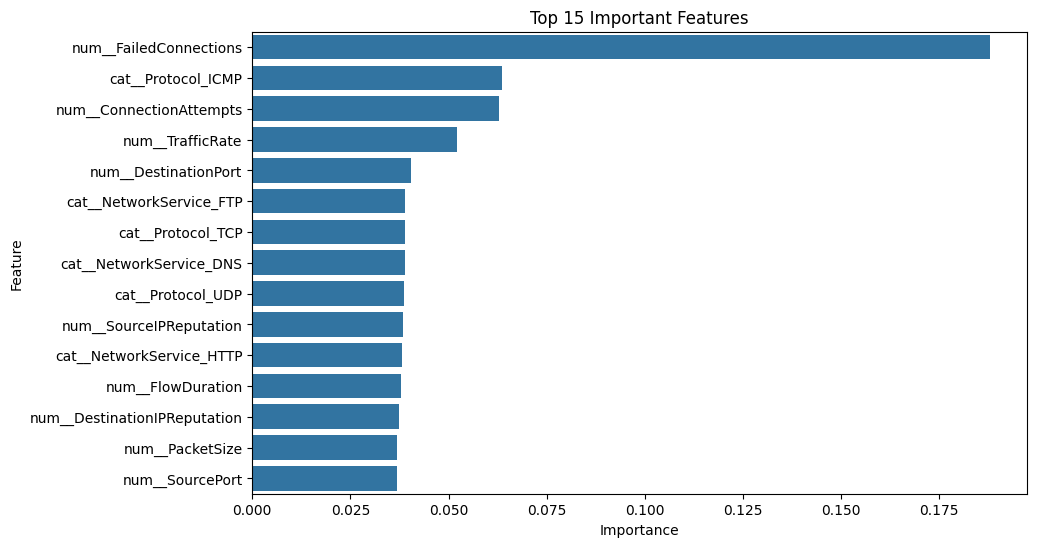

In [49]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature")
plt.title("Top 15 Important Features")
plt.show()

In [50]:
new_network = pd.DataFrame({
    "SourcePort": [45000],
    "DestinationPort": [22],
    "Protocol": ["TCP"],
    "PacketSize": [1200],
    "PacketCount": [90],
    "FlowDuration": [0.5],
    "BytesTransferred": [108000],
    "ConnectionAttempts": [8],
    "FailedConnections": [5],
    "TrafficRate": [216000],
    "SourceIPReputation": [0.2],
    "DestinationIPReputation": [0.8],
    "NetworkService": ["SSH"]
})

prediction = best_model.predict(new_network)[0]
probability = best_model.predict_proba(new_network)[0][1]

if prediction == 1:
    print("Prediction: Attack Detected!")
else:
    print("Prediction: Normal Traffic")

print("Attack Probability:", round(probability * 100, 2), "%")

Prediction: Attack Detected!
Attack Probability: 92.38 %


In [51]:
joblib.dump(best_model, "intrusion_detection_model.pkl")
print("Model Saved Successfully!")

Model Saved Successfully!


In [52]:
loaded_model = joblib.load("intrusion_detection_model.pkl")
prediction = loaded_model.predict(new_network)
print("Loaded Model Prediction:", prediction[0])

Loaded Model Prediction: 1
